# Exploring the TrashNet Dataset

### Understanding our images before building a model

Before we can teach a machine learning model to recognise different types of waste, we first need to understand the data we are working with.

**Purpose:** our project is an image classification task. We want to explore whether a model can recognise different types of waste from images and help people sort their waste correctly.

In this notebook we explore the TrashNet dataset, look at the images, investigate the categories and identify anything that might affect our models.

**Notebook structure**
1. Setup
2. Data quality: overview, corrupt files, duplicates
3. Dataset structure: class distribution, image size
4. Visual and pixel analysis: sample images, brightness, colour histograms
5. Preparing for modelling: the shared train/validation/test split

> Run the notebook with **Restart → Run All**: cells depend on variables created in the cells above them.

## The problem we want to solve

Sorting waste correctly is important for recycling. However, 
different types of materials can sometimes look similar.

We want to investigate how machine learning can help recognise 
waste through images.

Our dataset contains six categories of waste:

- Cardboard
- Glass
- Metal
- Paper
- Plastic
- Trash

The idea is simple: give the model an image and let it predict 
which category the waste belongs to.

But first, let's get to know our data!

## 1. Setup
### Imports and configuration
All shared code (paths, the split and the feature functions) lives in `src/data_utils.py`, so the model notebooks and the Streamlit app use exactly the same functions.

In [1]:
import hashlib, sys
from pathlib import Path

import numpy as np
import cv2
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm import tqdm

# Make `src/` importable from inside notebooks/
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.append(str(ROOT))

from src.data_utils import (CLASSES, load_image, color_histogram,
                          channel_histograms, basic_stats, average_hash,
                          extract_features, HSV_BINS)

from src.data_utils import DATASET_PATH, split_dataset
DATA_DIR = DATASET_PATH          # data/raw/Trashnet/dataset-resized (defined once in src/data_utils.py)
PROC_DIR = ROOT / "data" / "processed"
FIG_DIR  = ROOT / "reports" / "figures"
PROC_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
PALETTE = dict(zip(CLASSES, sns.color_palette("tab10", len(CLASSES))))

print(DATA_DIR.exists(), sorted(p.name for p in DATA_DIR.iterdir()))

True ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']


## 2. Data quality
### Dataset overview

We start by building an inventory with one row per image and summarising it per class. This answers:
- How many images and categories do we have?
- Do all images have the same size and colour format?
- Are any files corrupt?
- Are all categories represented equally?

In [2]:
# Build an inventory: one row per image
rows = []
for cls_dir in sorted(DATA_DIR.iterdir()):
    if not cls_dir.is_dir():
        continue
    for p in sorted(cls_dir.glob("*")):
        if p.suffix.lower() not in {".jpg", ".jpeg", ".png"}:
            continue
        rec = {"path": str(p), "label": cls_dir.name, "file": p.name,
               "file_kb": p.stat().st_size / 1024}
        try:
            with Image.open(p) as im:
                rec.update(width=im.width, height=im.height, mode=im.mode)
                im.verify()           # raises if the file is broken
            rec["corrupt"] = False
        except Exception:
            rec["corrupt"] = True
        rows.append(rec)

df = pd.DataFrame(rows)
print(df.shape)

(2527, 8)


In [3]:
summary = df.groupby("label").agg(
    images=("file", "count"),
    avg_size_kb=("file_kb", "mean"),
    width=("width", lambda s: ", ".join(map(str, s.unique()))),
    height=("height", lambda s: ", ".join(map(str, s.unique()))),
    mode=("mode", lambda s: ", ".join(s.unique())),
    corrupt=("corrupt", "sum"),
).round(1)
summary.insert(1, "percent", (summary["images"] / summary["images"].sum() * 100).round(1))
summary

,images,percent,avg_size_kb,width,height,mode,corrupt
label,,,,,,,
cardboard,403,15.9,18.4,512,384,RGB,0
glass,501,19.8,13.0,512,384,RGB,0
metal,410,16.2,17.3,512,384,RGB,0
paper,594,23.5,21.1,512,384,RGB,0
plastic,482,19.1,14.1,512,384,RGB,0
trash,137,5.4,13.8,512,384,RGB,0


**Findings**
- The dataset contains **2,527 images in 6 classes**: cardboard, glass, metal, paper, plastic and trash.
- All images are **512 × 384 pixels, RGB**, and **no files are corrupt**, so no cleaning is needed for format or size.
- The classes are **imbalanced** (paper 594 vs trash 137), see *Class distribution* below.
- The average file size differs between classes, from 13.0 KB (glass) to 21.1 KB (paper).

### Duplicates and near-duplicates

Before splitting our images into training and test sets, we need to check for duplicates and near-duplicates.

If almost identical images appear in both sets, the model may recognise images it has already seen. This can lead to misleadingly high test results.

We will check for:
- **Exact duplicates:** Identical image files.
- **Near-duplicates:** Images that look almost the same but may differ slightly.

**Goal:** Make sure our train, validation and test sets are independent, so we can trust our model evaluation.

In [4]:
# Fingerprint every image
df["md5"] = [hashlib.md5(Path(p).read_bytes()).hexdigest() for p in df["path"]]   # identical bytes
df["ahash"] = [average_hash(p) for p in tqdm(df["path"])]                         # looks the same

# Exact duplicates: one row per group of identical files
exact = df[df.duplicated("md5", keep=False)]
dup_pairs = (exact.groupby("md5")
                  .agg(files=("file", " = ".join),
                       labels=("label", " / ".join),
                       n_classes=("label", "nunique"))
                  .reset_index(drop=True))
dup_pairs["same_class"] = dup_pairs["n_classes"] == 1
dup_pairs = dup_pairs.drop(columns="n_classes")

# Near-duplicates that are NOT already exact copies
near = df[df.duplicated("ahash", keep=False)]
only_near = near[~near["md5"].isin(exact["md5"])]

print(f"Exact duplicate groups:   {len(dup_pairs)}  ({len(exact)} files)")
print(f"  ...with different labels: {(~dup_pairs['same_class']).sum()}")
print(f"Extra near-duplicate files: {len(only_near)}")
dup_pairs

100%|██████████| 2527/2527 [00:04<00:00, 590.54it/s]

Exact duplicate groups:   3  (6 files)
  ...with different labels: 3
Extra near-duplicate files: 0


,files,labels,same_class
0,glass115.jpg = metal91.jpg,glass / metal,False
1,glass176.jpg = plastic152.jpg,glass / plastic,False
2,glass389.jpg = plastic332.jpg,glass / plastic,False


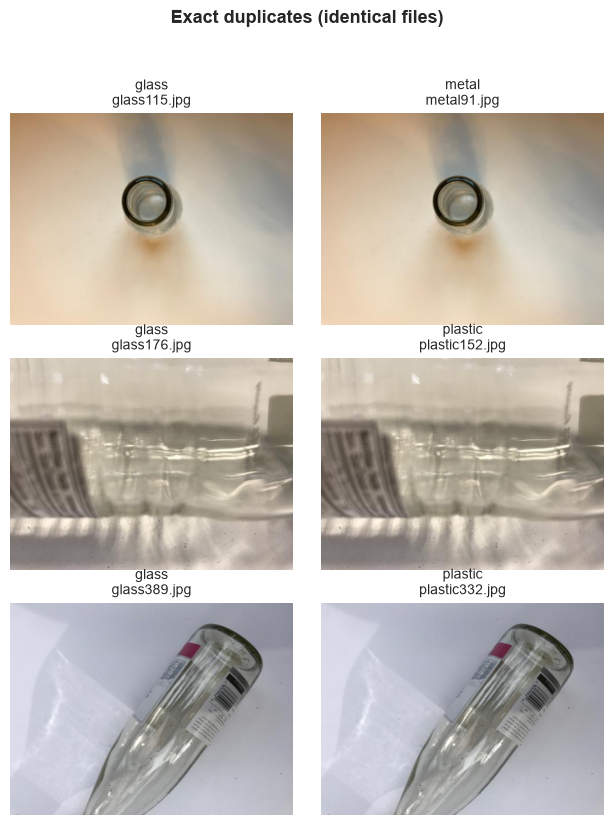

Near-duplicates (look almost the same): none found


In [5]:
def show_groups(dupes, key, title, filename, max_groups=10):
    """Show each group of duplicate images in one row, with label and file name."""
    groups = [g for _, g in dupes.groupby(key)][:max_groups]
    if not groups:
        print(f"{title}: none found")
        return
    n_cols = max(len(g) for g in groups)
    fig, axes = plt.subplots(len(groups), n_cols,
                             figsize=(3.2 * n_cols, 2.8 * len(groups)), squeeze=False)
    for r, g in enumerate(groups):
        for c in range(n_cols):
            ax = axes[r, c]
            ax.axis("off")
            if c < len(g):
                row = g.iloc[c]
                ax.imshow(Image.open(row["path"]))
                ax.set_title(f'{row["label"]}\n{row["file"]}', fontsize=10)
    fig.suptitle(title, fontsize=13, fontweight="bold")
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.savefig(FIG_DIR / filename, dpi=120)
    plt.show()

show_groups(exact, "md5", "Exact duplicates (identical files)", "00a_exact_duplicates.png")
show_groups(only_near, "ahash", "Near-duplicates (look almost the same)", "00b_near_duplicates.png")

**Findings**
- We found **3 photos that appear twice**, each time under a **different class** (glass/metal, glass/plastic, glass/plastic). These are labelling errors in the original TrashNet dataset.
- A model cannot learn the correct label from contradictory examples, and if the copies end up in different splits, the test is unfair.
- `split_dataset()` keeps only the **first copy** of each duplicate (the one labelled *glass*) and drops the other, so no duplicate can leak between splits. This is why metal has 409 and plastic 480 images in the split. The true label of these 3 photos was not verified.
- No other near-duplicates were found.

## 3. Dataset structure

### Class distribution
How are the images distributed across the six categories? This matters for how we split the data, train the models and choose evaluation metrics.

,n,%
label,,
cardboard,403,15.9
glass,501,19.8
metal,410,16.2
paper,594,23.5
plastic,482,19.1
trash,137,5.4


Imbalance ratio (max/min): 4.34


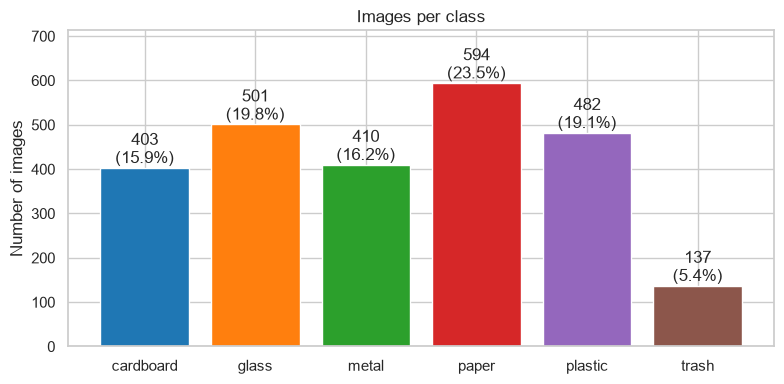

In [6]:
counts = df["label"].value_counts().reindex(CLASSES)
pct = (counts / counts.sum() * 100).round(1)
display(pd.DataFrame({"n": counts, "%": pct}))
print("Imbalance ratio (max/min):", round(counts.max() / counts.min(), 2))

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(counts.index, counts.values, color=[PALETTE[c] for c in counts.index])
ax.bar_label(bars, labels=[f"{n}\n({p}%)" for n, p in zip(counts, pct)])
ax.set_title("Images per class"); ax.set_ylabel("Number of images")
ax.margins(y=0.2)
plt.tight_layout(); plt.savefig(FIG_DIR / "01_class_distribution.png", dpi=150); plt.show()

**Findings**
- **paper** is the largest class (594 images, 23.5 %) and **trash** the smallest (137 images, 5.4 %), an imbalance ratio of **4.34**.
- glass (501) and plastic (482) are close in size, and cardboard (403) and metal (410) are mid-sized.
- A model that rarely predicts *trash* could still score high accuracy, so we evaluate with **macro-F1** and per-class recall.
- The imbalance is moderate, so we use **class weights** instead of oversampling, together with a stratified split.

### Image size and file size
Our models need images with a consistent input size and colour format, and the aspect ratio matters when resizing to 224 × 224 so that objects are not unnecessarily distorted or cropped. File size gives a quick hint of texture: detailed images compress less.

width  height  mode
512    384     RGB     2527
dtype: int64

count    2.527000e+03
mean     1.333333e+00
std      2.220886e-16
min      1.333333e+00
25%      1.333333e+00
50%      1.333333e+00
75%      1.333333e+00
max      1.333333e+00
Name: aspect, dtype: float64


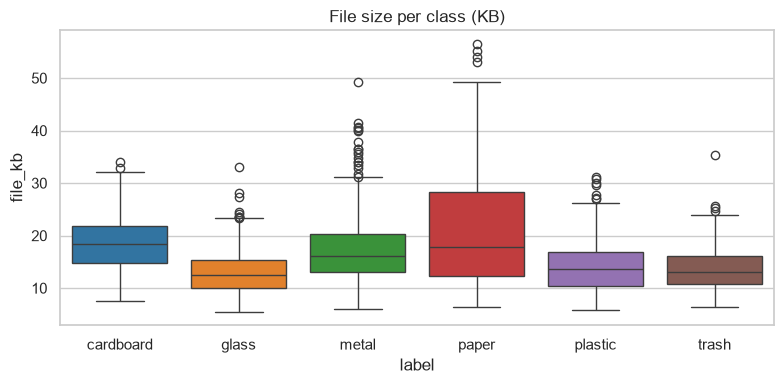

In [7]:
display(df.groupby(["width", "height", "mode"]).size())
df["aspect"] = df["width"] / df["height"]
print(df["aspect"].describe())

fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=df, x="label", y="file_kb", order=CLASSES,
            palette=PALETTE, hue="label", legend=False, ax=ax)
ax.set_title("File size per class (KB)")
plt.tight_layout(); plt.savefig(FIG_DIR / "02_file_size.png", dpi=150); plt.show()

**Findings**
- All images are 512 × 384 RGB (4:3), so one resize rule works for the whole dataset: **224 × 224** for transfer learning (a smaller size is possible for a simple CNN).
- Resizing 4:3 to a square slightly distorts objects; padding or center-cropping avoids this. We choose one method in the preprocessing pipeline.
- File size differs by class (glass smallest, paper largest), which hints at differences in texture and detail.

## 4. Visual and pixel analysis

### Sample images per class

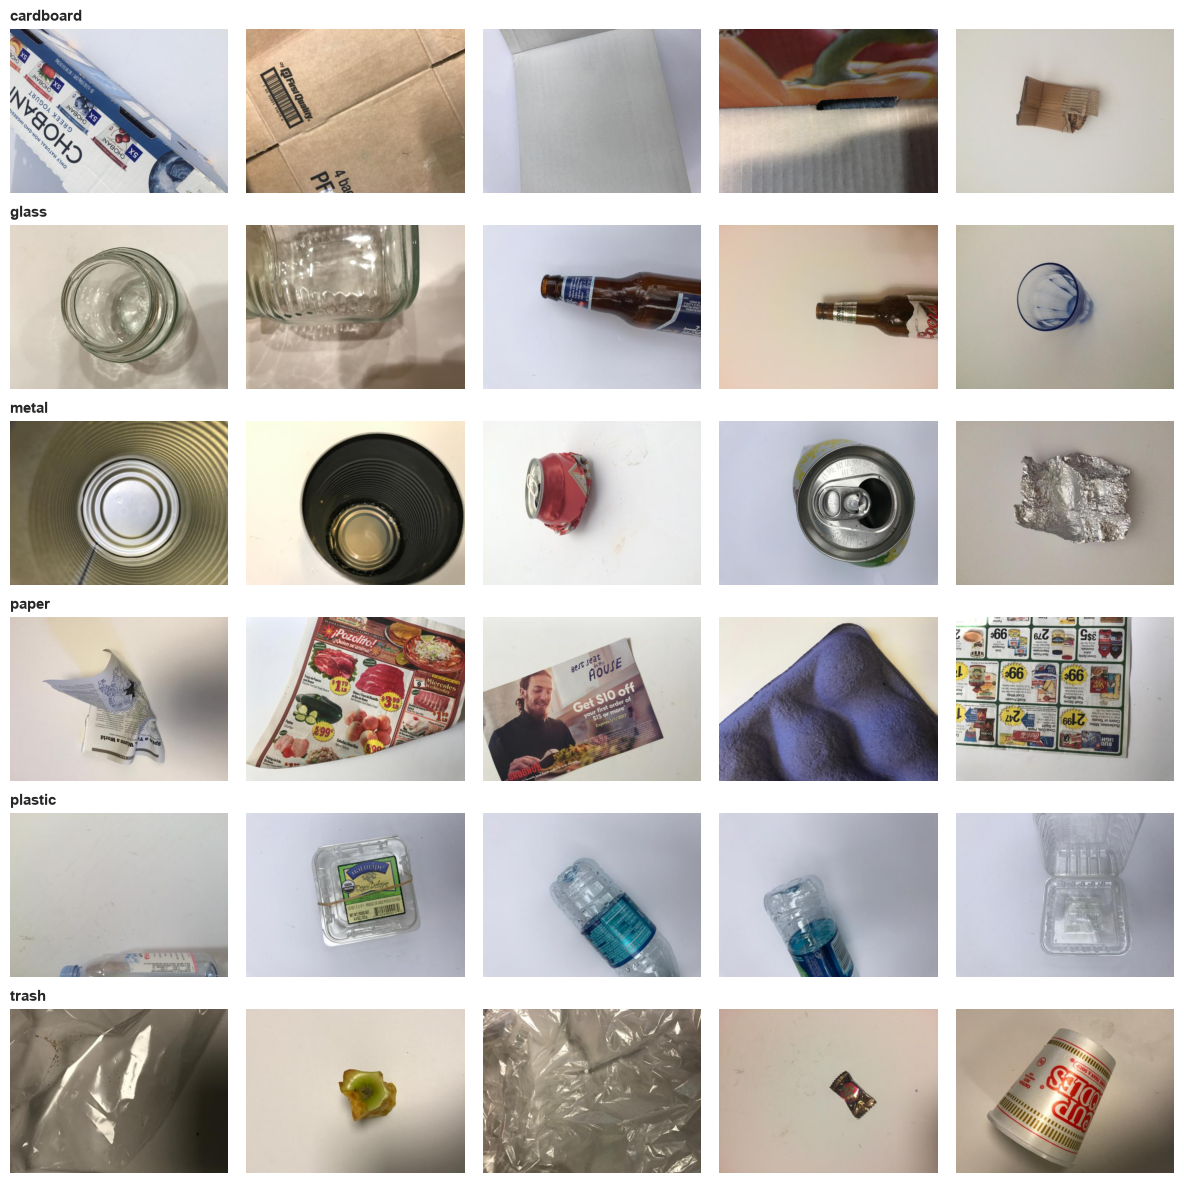

In [8]:
N = 5
fig, axes = plt.subplots(len(CLASSES), N, figsize=(N * 2.4, len(CLASSES) * 2))
for r, cls in enumerate(CLASSES):
    sample = df[df["label"] == cls].sample(N, random_state=SEED)
    for c, p in enumerate(sample["path"]):
        axes[r, c].imshow(Image.open(p)); axes[r, c].axis("off")
    axes[r, 0].set_title(cls, loc="left", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.savefig(FIG_DIR / "03_sample_grid.png", dpi=120); plt.show()

**Findings**
- Each image shows **one object on a plain white/grey background** with similar lighting, so the images look like studio photos.
- Some classes are visually distinct (brown **cardboard**, shiny **metal**), while **glass vs plastic** (both transparent) and **paper vs cardboard** (similar material) look easy to confuse.
- **trash** has no shared look; it is a mix of different objects, which together with its small size makes it the hardest class.
- **Risk:** real photos uploaded in the Streamlit app will have messy backgrounds and varied lighting, so we use **augmentation** (rotation, flips, colour jitter, crops) to make the model more robust.

### Brightness, contrast and saturation
Do the classes differ in simple pixel properties? The table shows the mean per class; the boxplots show the spread.

100%|██████████| 2527/2527 [00:07<00:00, 343.40it/s]


,brightness,contrast,saturation
label,,,
cardboard,152.8,44.8,78.7
glass,171.4,47.0,41.2
metal,158.8,53.6,44.2
paper,165.8,46.8,37.4
plastic,170.3,36.9,31.5
trash,168.0,43.1,49.8


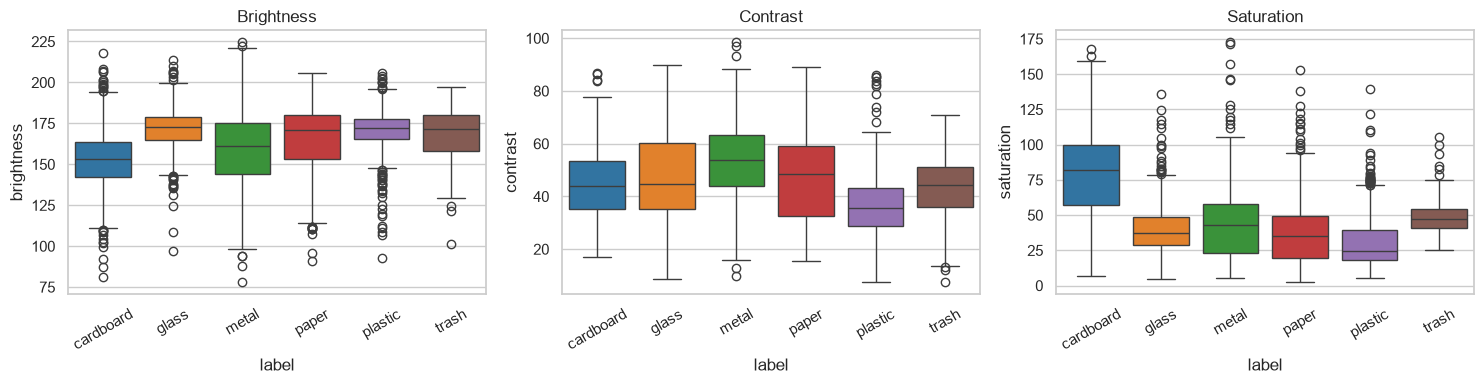

In [9]:
stats = pd.DataFrame([basic_stats(load_image(p)) for p in tqdm(df["path"])])
df = pd.concat([df.drop(columns=stats.columns, errors="ignore").reset_index(drop=True), stats], axis=1)
display(df.groupby("label")[["brightness", "contrast", "saturation"]].mean().round(1))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["brightness", "contrast", "saturation"]):
    sns.boxplot(data=df, x="label", y=col, order=CLASSES,
                palette=PALETTE, hue="label", legend=False, ax=ax)
    ax.set_title(col.capitalize())
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig(FIG_DIR / "04_brightness_contrast.png", dpi=150)
plt.show()

### Background check
The outer 5 pixels of each image are almost always background. If their brightness differs between classes, a model could learn the background instead of the object (**shortcut learning**).

In [10]:
border = []
for p in df["path"]:
    a = load_image(p)
    edge = np.concatenate([a[:5].reshape(-1, 3), a[-5:].reshape(-1, 3),
                           a[:, :5].reshape(-1, 3), a[:, -5:].reshape(-1, 3)])
    border.append(edge.mean())
df["border_brightness"] = border
df.groupby("label")["border_brightness"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
cardboard,403.0,158.3,31.8,73.2,137.3,151.3,175.7,252.9
glass,501.0,185.0,17.6,127.6,175.5,187.9,196.4,250.3
metal,410.0,178.4,26.9,80.2,162.8,181.2,196.0,241.1
paper,594.0,181.9,15.8,107.2,174.8,183.0,191.7,223.2
plastic,482.0,182.0,17.2,101.1,174.5,185.3,192.5,227.9
trash,137.0,174.5,21.0,86.8,166.9,179.1,186.3,225.4


### Normalisation values
Mean and standard deviation per colour channel, compared with ImageNet (the dataset pretrained models were trained on).

In [11]:
sample = df.groupby("label").sample(min(100, counts.min()), random_state=SEED)
px = np.stack([load_image(p) / 255.0 for p in sample["path"]])
mean, std = px.mean(axis=(0, 1, 2)), px.std(axis=(0, 1, 2))
print("TrashNet mean:", mean.round(3), " std:", std.round(3))
print("ImageNet mean: [0.485 0.456 0.406]  std: [0.229 0.224 0.225]")

TrashNet mean: [0.673 0.635 0.595]  std: [0.203 0.206 0.229]
ImageNet mean: [0.485 0.456 0.406]  std: [0.229 0.224 0.225]


 **Findings:  What Do Brightness, Contrast and Background Tell Us?**

- **Cardboard** is darker but much more saturated, making colour a useful way to recognise it.
- **Glass and plastic** are the brightest, while plastic also has the lowest contrast and saturation.
- **Metal** has the highest contrast, probably due to shiny reflections.
- Brightness and contrast overlap between classes, so colour seems more useful for separating materials.

**Background:** Cardboard often has a darker border because many images are close-ups. The model might learn the background instead of the material.

**Normalisation**
- TrashNet mean (R, G, B): **[0.673, 0.635, 0.595]**, std: **[0.203, 0.206, 0.229]**
- ImageNet mean:**[0.485, 0.456, 0.406]**, std: **[0.229, 0.224, 0.225]**
- TrashNet is **much brighter** than ImageNet because of the light backgrounds.
- **Decision:** For our own CNN, we use TrashNet values. For transfer learning, we keep ImageNet values because those models were originally trained with them.

### Colour histogram features
A colour histogram counts how many pixels fall into each colour "bin". It ignores *where* the pixels are, so it is unaffected by rotation and position, and it describes the colour content of an image as a fixed-length vector.

We use **HSV (Hue, Saturation, Value)** instead of **RGB (Red, Green, Blue)**:
- **Hue:** which colour (red, green, blue, ...)
- **Saturation:** how strong or pale the colour is
- **Value:** how bright it is

Because hue is separated from brightness, the features are more robust to lighting differences. With 8 hue × 4 saturation × 4 value bins, every image becomes a **128-dimensional feature vector**, normalised so it sums to 1.

#### From image to feature vector
The function `color_histogram()` takes a whole image (a 3-D array: height × width × 3 colour channels) and returns **one row of numbers**. That row can be used directly as input to a classic ML model.

Image in:   (384, 512, 3) = 589,824 numbers
Vector out: (1, 128) = 128 numbers


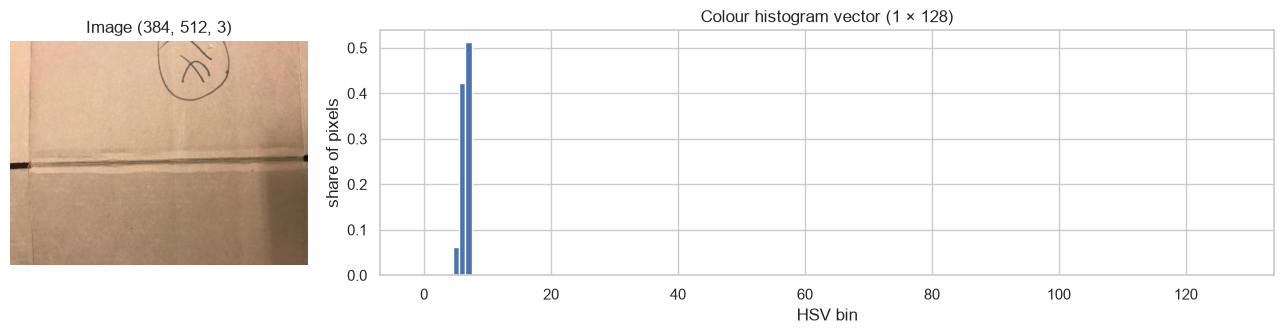

In [12]:
p = df["path"].iloc[0]
original = np.asarray(Image.open(p).convert("RGB"))
vector = color_histogram(load_image(p))

print("Image in:  ", original.shape, "=", f"{original.size:,}", "numbers")
print("Vector out:", vector.reshape(1, -1).shape, "=", vector.size, "numbers")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.5), gridspec_kw={"width_ratios": [1, 3]})
axes[0].imshow(original)
axes[0].axis("off")
axes[0].set_title(f"Image {original.shape}")
axes[1].bar(range(vector.size), vector, width=1.0)
axes[1].set_title(f"Colour histogram vector (1 × {vector.size})")
axes[1].set_xlabel("HSV bin")
axes[1].set_ylabel("share of pixels")
plt.tight_layout()
plt.savefig(FIG_DIR / "05a_image_to_vector.png", dpi=150)
plt.show()

An image of 512 × 384 × 3 = 589,824 numbers is reduced to a vector of only **128 numbers**. Stacking one vector per image gives the feature matrix **X (2,527 × 128)**: a regular table of 2,527 observations × 128 variables that classic ML models can use directly.

**Example:** this cardboard close-up puts almost all pixels into 3 of the 128 bins (bins 5–7): reddish-orange hue, low-to-medium saturation, medium-to-high brightness, i.e. the muted brown of cardboard. The other 125 bins are empty, so the vector is sparse but very characteristic. The image has no visible background, a first sign that not all TrashNet photos follow the same studio style.

#### RGB channel histograms per class (intuition)

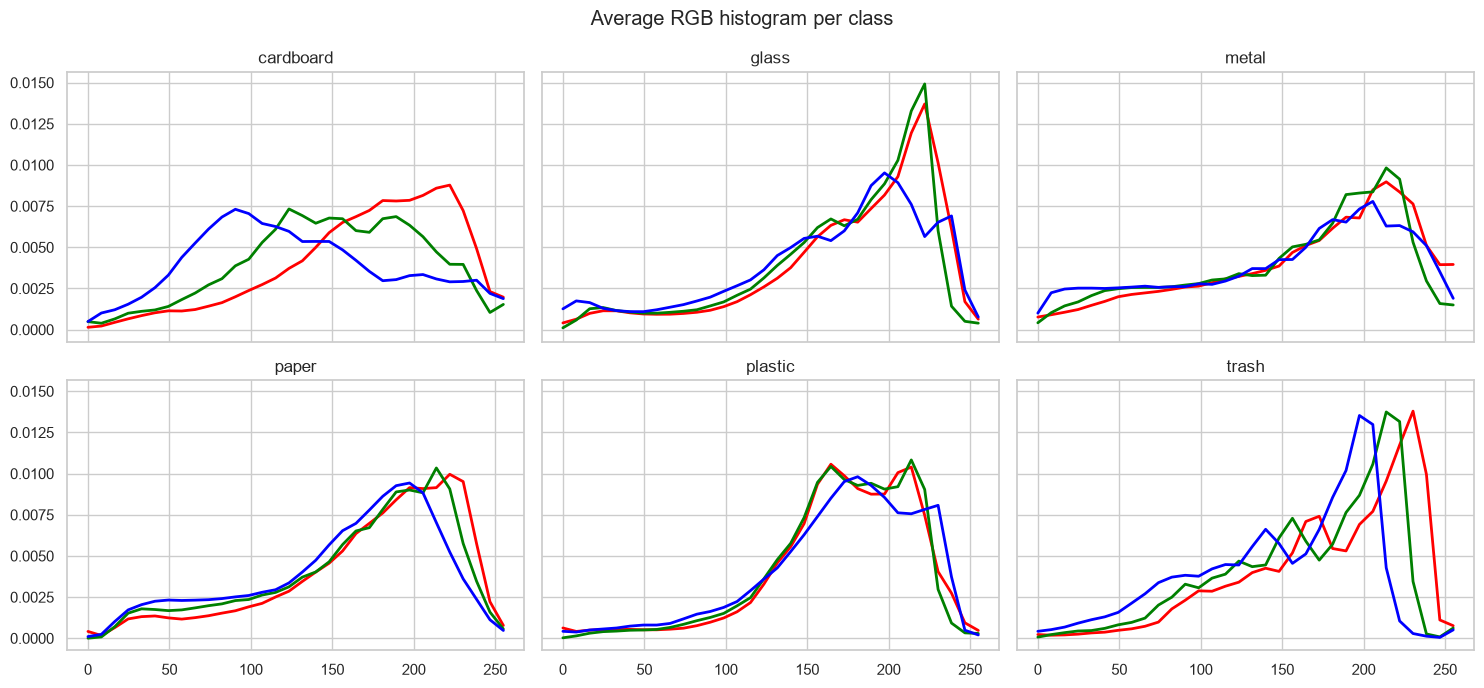

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharex=True, sharey=True)
x = np.linspace(0, 255, 32)
for ax, cls in zip(axes.flat, CLASSES):
    paths = df.loc[df["label"] == cls, "path"]
    h = np.mean([channel_histograms(load_image(p)) for p in paths], axis=0)
    for ch, colour in enumerate(["red", "green", "blue"]):
        ax.plot(x, h[ch], color=colour, lw=2)
    ax.set_title(cls)
fig.suptitle("Average RGB histogram per class")
plt.tight_layout()
plt.savefig(FIG_DIR / "05_rgb_hist_per_class.png", dpi=150)
plt.show()

**Findings**
- **Cardboard** is the only class where the channels clearly separate: red dominates at high values while blue peaks much lower, which is the warm brown of cardboard.
- **Glass, paper and plastic** have the three channels close together, i.e. neutral greys and whites from the background and pale objects.
- **Trash** and **glass** show sharp peaks around 200–230 (light background); **metal** is spread over the whole range because of reflections and dark edges.

#### Extract HSV features and save them
The model notebooks can load these files directly instead of recomputing them.

In [14]:
X_hist = extract_features(df["path"], fn=color_histogram)
y = df["label"].values
print("Feature matrix:", X_hist.shape)        # (n_images, 128)

np.save(PROC_DIR / "X_color_hist.npy", X_hist)
df[["path", "label"]].assign(path=[Path(p).relative_to(ROOT).as_posix() for p in df["path"]]) \
    .to_csv(PROC_DIR / "color_hist_index.csv", index=False)

Feature matrix: (2527, 128)


#### Background share: how many images are close-ups?
A grey/beige/white background falls into the HSV bins with **low saturation and medium-to-high brightness**. Summing those bins gives the share of background-like pixels per image. The sanity-check images below test whether the metric matches what we see.

Images with < 10 % background pixels:


label
cardboard    148
glass          2
metal          2
paper          1
plastic        0
trash          0
dtype: int64

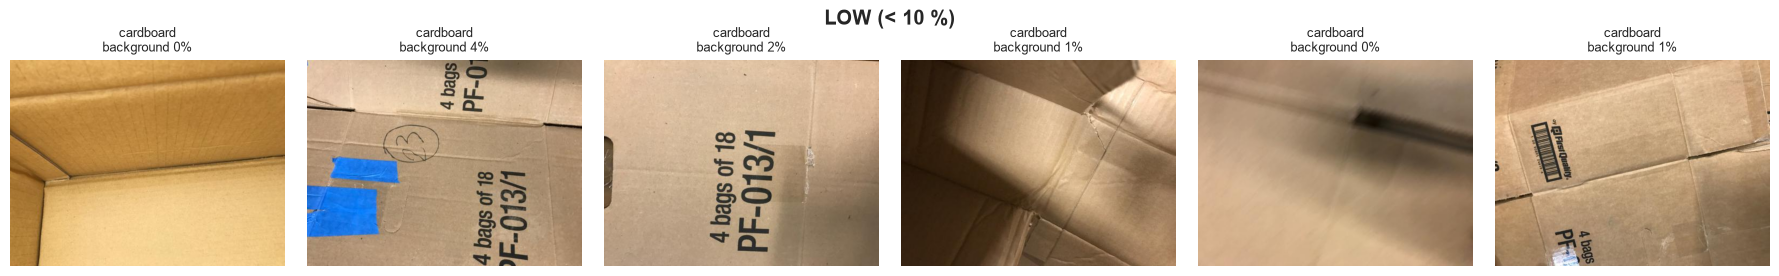

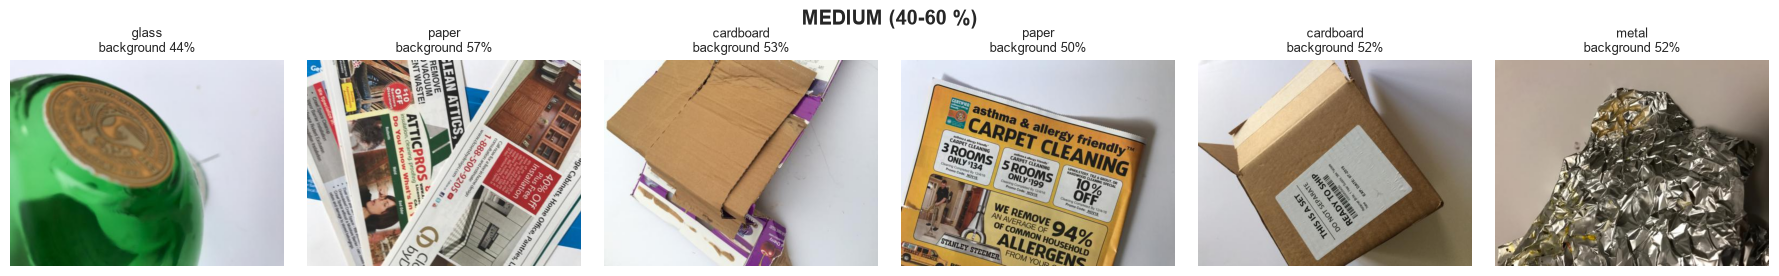

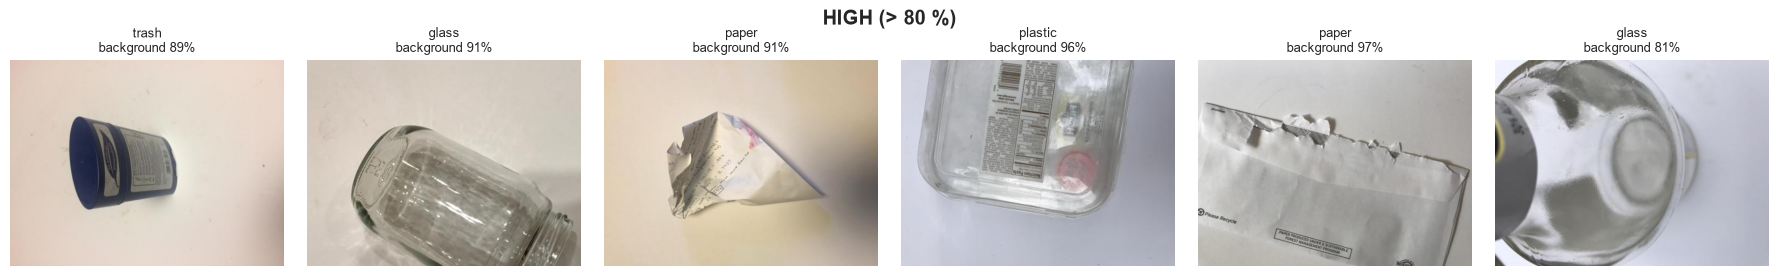

In [15]:
# Background = low saturation AND medium-to-high brightness (grey/beige/white surfaces)
bg_bins = [h * 16 + 0 * 4 + v for h in range(8) for v in (2, 3)]
df["background_share"] = X_hist[:, bg_bins].sum(axis=1)

print("Images with < 10 % background pixels:")
display(df[df["background_share"] < 0.10].groupby("label").size().reindex(CLASSES, fill_value=0))

# Sanity check: 6 random images with low, medium and high background share
for name, part in [("LOW (< 10 %)", df[df["background_share"] < 0.10]),
                   ("MEDIUM (40-60 %)", df[df["background_share"].between(0.4, 0.6)]),
                   ("HIGH (> 80 %)", df[df["background_share"] > 0.80])]:
    if len(part) == 0:
        print(name, ": none")
        continue
    pick = part.sample(min(6, len(part)), random_state=SEED)
    fig, axes = plt.subplots(1, len(pick), figsize=(3 * len(pick), 2.8), squeeze=False)
    for ax, (_, row) in zip(axes[0], pick.iterrows()):
        ax.imshow(Image.open(row["path"]))
        ax.axis("off")
        ax.set_title(f"{row['label']}\nbackground {row['background_share']:.0%}", fontsize=9)
    fig.suptitle(name, fontweight="bold")
    plt.tight_layout()
    plt.show()

**Findings**
- **148 of 403 cardboard images (37 %)** are close-ups with < 10 % background, compared with only **5 of 2,124 (0.2 %)** in all other classes.
- Risk: the model may learn "no background = cardboard" as a shortcut. We counter this with crop/zoom augmentation.
- Limitation: transparent objects and white paper are partly counted as background.

#### Mean HSV histogram per class
The average colour histogram of each class. The colour strip on top shows the colour each bin stands for; only bins with at least 2 % of pixels in some class are shown.

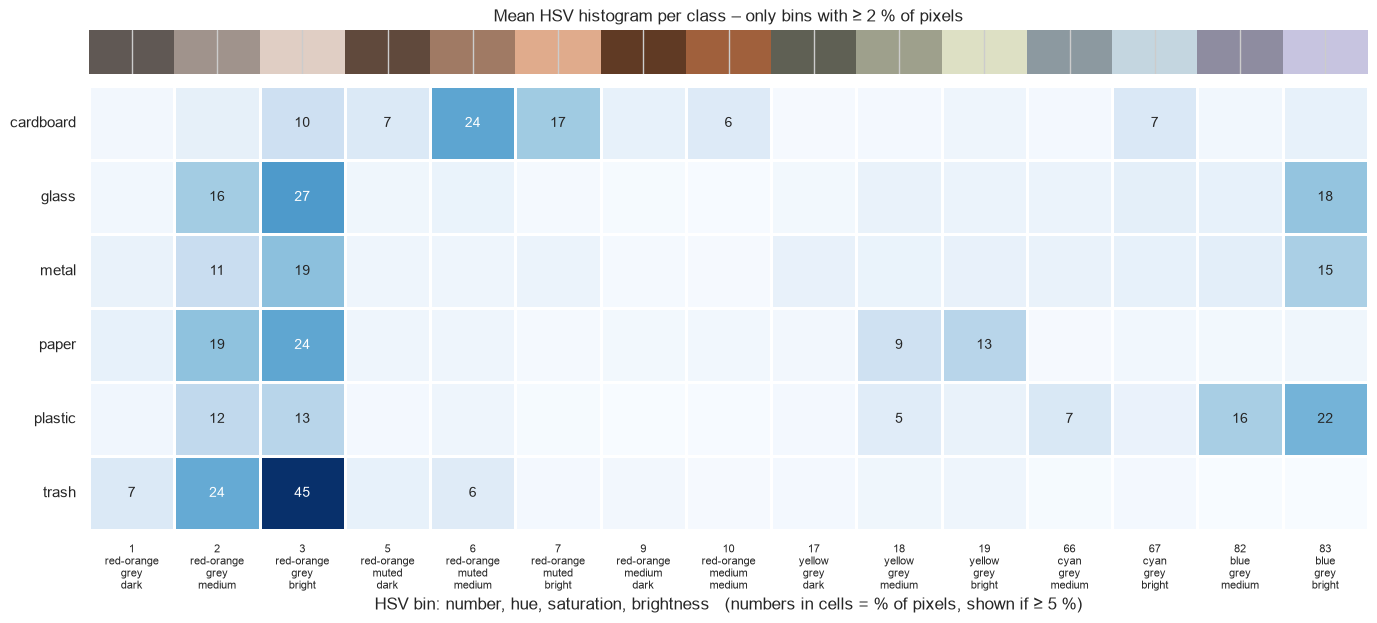

In [16]:
HUE_NAMES = ["red-orange", "yellow", "green", "green-cyan", "cyan", "blue", "purple", "pink"]
SAT_NAMES = ["grey", "muted", "medium", "vivid"]
VAL_NAMES = ["very dark", "dark", "medium", "bright"]
n_h, n_s, n_v = HSV_BINS

def bin_info(b):
    """Bin number -> readable name and its centre colour (RGB 0-1)."""
    h, s, v = b // (n_s * n_v), (b // n_v) % n_s, b % n_v
    hsv = np.uint8([[[(h + 0.5) * 180 / n_h, (s + 0.5) * 256 / n_s, (v + 0.5) * 256 / n_v]]])
    rgb = cv2.cvtColor(hsv, cv2.COLOR_HSV2RGB)[0, 0] / 255
    return f"{b}\n{HUE_NAMES[h]}\n{SAT_NAMES[s]}\n{VAL_NAMES[v]}", rgb

mean_hist = pd.DataFrame(X_hist).groupby(y).mean().reindex(CLASSES)

# Keep only bins that matter: at least 2 % of pixels in some class
keep = [b for b in mean_hist.columns if mean_hist[b].max() >= 0.02]
names, swatches = zip(*[bin_info(b) for b in keep])
data = mean_hist[keep] * 100                     # percent of pixels

fig, (ax_sw, ax) = plt.subplots(2, 1, figsize=(max(8, 1.1 * len(keep)), 6.5), sharex=True,
                                gridspec_kw={"height_ratios": [0.6, 6], "hspace": 0.05})

# Top strip: the actual colour each bin stands for
ax_sw.imshow([list(swatches)], aspect="auto", extent=(0, len(keep), 0, 1))
ax_sw.set_yticks([])
ax_sw.set_title("Mean HSV histogram per class – only bins with ≥ 2 % of pixels", fontsize=12)
for spine in ax_sw.spines.values():
    spine.set_visible(False)

# Heatmap: darker blue = more pixels; numbers shown where ≥ 5 %
labels = data.round(0).astype(int).astype(str).where(data >= 5, "")
sns.heatmap(data, cmap="Blues", ax=ax, cbar=False, linewidths=2, linecolor="white",
            annot=labels, fmt="", annot_kws={"fontsize": 10})
ax.set_xticks(np.arange(len(keep)) + 0.5)
ax.set_xticklabels(names, rotation=0, fontsize=8)
ax.set_xlabel("HSV bin: number, hue, saturation, brightness   (numbers in cells = % of pixels, shown if ≥ 5 %)")
ax.set_ylabel("")
ax.tick_params(axis="y", rotation=0)

plt.savefig(FIG_DIR / "06_hsv_hist_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

**Findings**
- Most pixels fall into a few **low-saturation bins** (greys, whites, beiges); vivid colours are rare.
- **Cardboard** is the only class with large shares in the **muted brown bins 5–7** (7 + 24 + 17 %), so colour should separate it well.
- **Paper** stands out with **warm, yellowish-white bins 18–19** (9 + 13 %).
- **Glass, metal and plastic** are the classes with a large share in the **bluish-grey bin 83** (18, 15 and 22 %); plastic also uses bins 66 and 82. We expect colour alone to confuse these three.
- **Trash** is dominated by warm grey background bins 2–3 (24 + 45 %), so its colour mostly describes the background, not the object.

#### How similar are the classes' colours? (Bhattacharyya distance)
Low distance = similar colours. Those class pairs are hard to separate by colour alone.

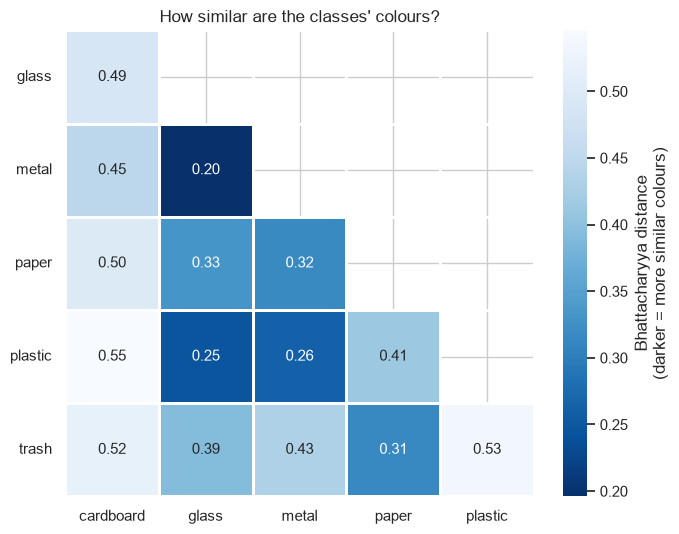

In [17]:
H = mean_hist.values.astype(np.float32)
dist = np.array([[cv2.compareHist(H[i], H[j], cv2.HISTCMP_BHATTACHARYYA)
                  for j in range(len(CLASSES))] for i in range(len(CLASSES))])

# Show each pair once: lower triangle without the diagonal (always 0)
dist_df = pd.DataFrame(dist, CLASSES, CLASSES).iloc[1:, :-1]
mask = np.triu(np.ones(dist_df.shape, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(dist_df, mask=mask, cmap="Blues_r", annot=True, fmt=".2f",
            linewidths=2, linecolor="white", annot_kws={"fontsize": 11}, ax=ax,
            cbar_kws={"label": "Bhattacharyya distance\n(darker = more similar colours)"})
ax.set_title("How similar are the classes' colours?", fontsize=12)
ax.tick_params(axis="y", rotation=0)
plt.tight_layout()
plt.savefig(FIG_DIR / "07_hist_distance.png", dpi=150)
plt.show()

**Findings**
- **Glass, metal and plastic** have the most similar colours (distances 0.20–0.26), so we expect the colour model to confuse them.
- **Cardboard** differs most from all other classes (0.45–0.55), matching its distinct brown bins.

#### Do the classes form clusters? (PCA and t-SNE)
Both methods are **unsupervised**: they reduce the 128 colour features to 2 dimensions without using the labels. The labels are only added afterwards as colours, to see whether the classes form natural groups.

In [18]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

Xs = StandardScaler().fit_transform(X_hist)
pca = PCA(n_components=2, random_state=SEED).fit(Xs)
Z_pca = pca.transform(Xs)
print(f"PCA: 2 components explain {pca.explained_variance_ratio_.sum():.0%} of the variance")

Z_tsne = TSNE(n_components=2, perplexity=30, random_state=SEED).fit_transform(Xs)   # takes 1-2 minutes

PCA: 2 components explain 9% of the variance


Each panel highlights one class in its colour; grey dots are all other images. t-SNE axes have no units or meaning: only which points lie close together matters, so the axis values are hidden.

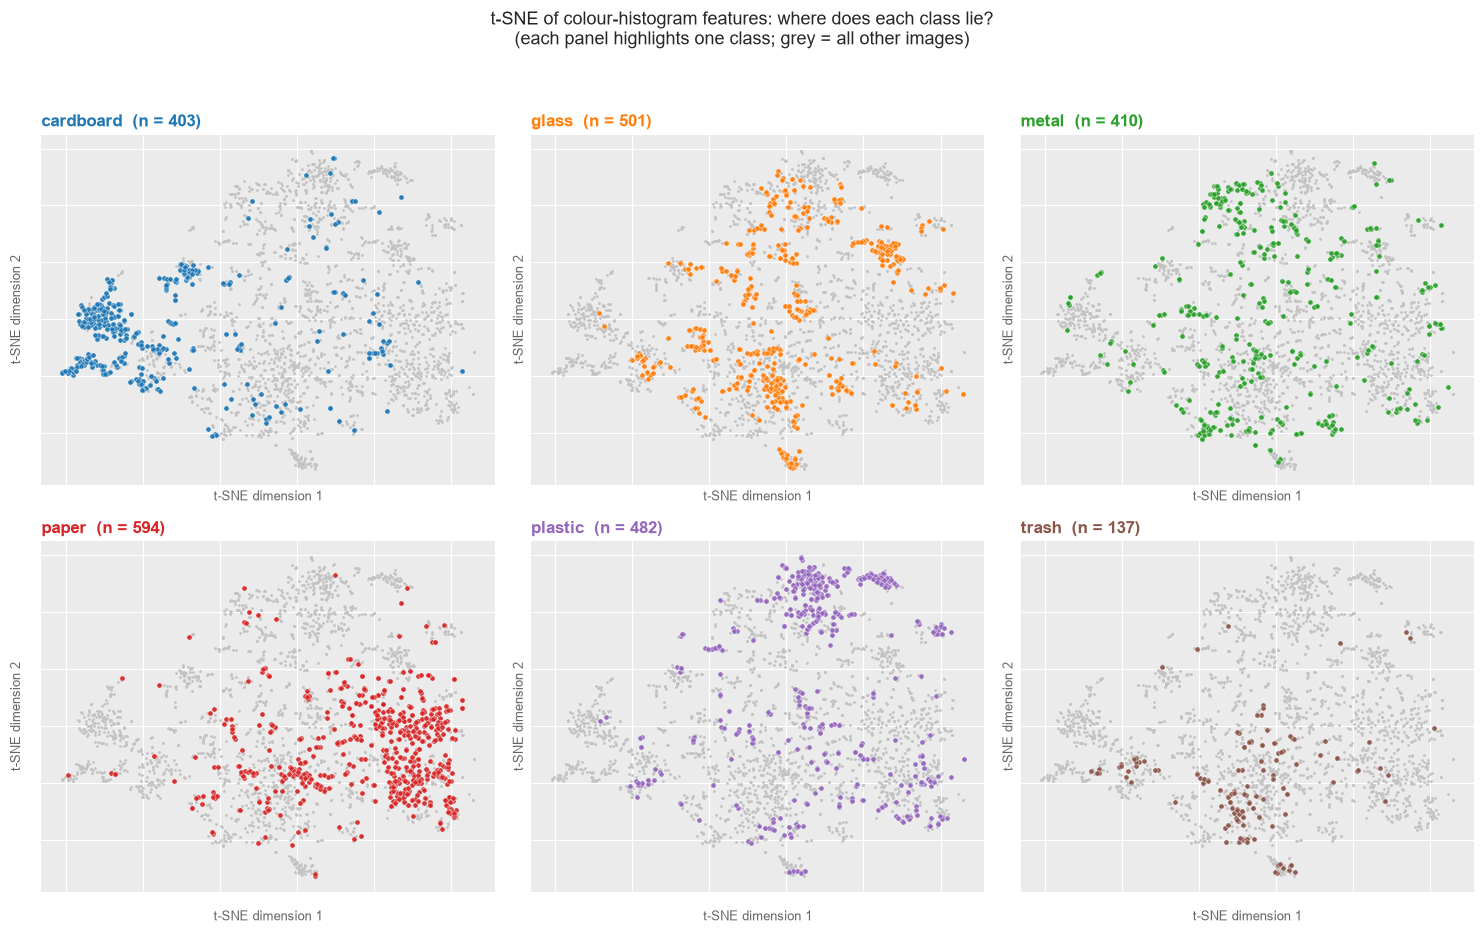

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9.5), sharex=True, sharey=True)
for ax, cls in zip(axes.flat, CLASSES):
    is_cls = y == cls
    ax.set_facecolor("#ebebeb")                      # soft grey panel instead of white
    ax.grid(color="white", linewidth=0.8)
    # all other images as grey background dots
    ax.scatter(Z_tsne[~is_cls, 0], Z_tsne[~is_cls, 1], s=4, color="#c2c2c2", linewidths=0)
    # this class on top, bigger and with a thin white edge so it pops
    ax.scatter(Z_tsne[is_cls, 0], Z_tsne[is_cls, 1], s=14, color=PALETTE[cls],
               alpha=0.95, edgecolors="white", linewidths=0.3)
    ax.set_title(f"{cls}  (n = {is_cls.sum()})", fontsize=12, fontweight="bold",
                 color=PALETTE[cls], loc="left")
    ax.set_xticklabels([])
    ax.set_yticklabels([])
    ax.set_xlabel("t-SNE dimension 1", fontsize=9, color="#666666")
    ax.set_ylabel("t-SNE dimension 2", fontsize=9, color="#666666")
    for spine in ax.spines.values():
        spine.set_visible(False)
fig.suptitle("t-SNE of colour-histogram features: where does each class lie?\n"
             "(each panel highlights one class; grey = all other images)", fontsize=13)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig(FIG_DIR / "08_tsne_per_class.png", dpi=150)
plt.show()

**Findings**
- PCA explains only **9 %** of the variance in 2 components, so the colour information is spread over many dimensions and is not linear; t-SNE shows the structure better.
- **Cardboard** forms a **dense cluster on the left** (likely the close-ups), while its remaining images are scattered among the other classes.
- **Paper** (right) and **plastic** (top) have their own dense regions but also spread into other areas.
- **Glass, metal and trash** are spread across the map in many small groups, mixed with the other classes, so colour alone separates them poorly.
- **Next step:** in the transfer-learning notebook we repeat this t-SNE on CNN features to see whether these classes separate better.

#### How far does colour alone get? (quick baseline)
This is not the final model, just a test of **how much information the colour histograms carry**. We train three models on the 128 colour features and compare them with 5-fold stratified cross-validation:

- **Dummy classifier:** always predicts the largest class (paper). It sets the floor; any useful model must beat it.
- **Logistic regression:** a simple linear model.
- **Random forest:** a non-linear model that can combine colour bins.

We compare **accuracy** and **macro-F1**. The confusion matrix shows *which* classes colour mixes up, so we can check the predictions from the heatmap, the distance matrix and the t-SNE.

,accuracy,macro_F1
Dummy (most frequent),0.235,0.063
LogReg,0.662,0.639
RandomForest,0.789,0.770


              precision    recall  f1-score   support

   cardboard       0.86      0.85      0.86       403
       glass       0.77      0.76      0.77       501
       metal       0.75      0.74      0.75       410
       paper       0.79      0.88      0.83       594
     plastic       0.81      0.75      0.78       482
       trash       0.64      0.63      0.63       137

    accuracy                           0.79      2527
   macro avg       0.77      0.77      0.77      2527
weighted avg       0.79      0.79      0.79      2527



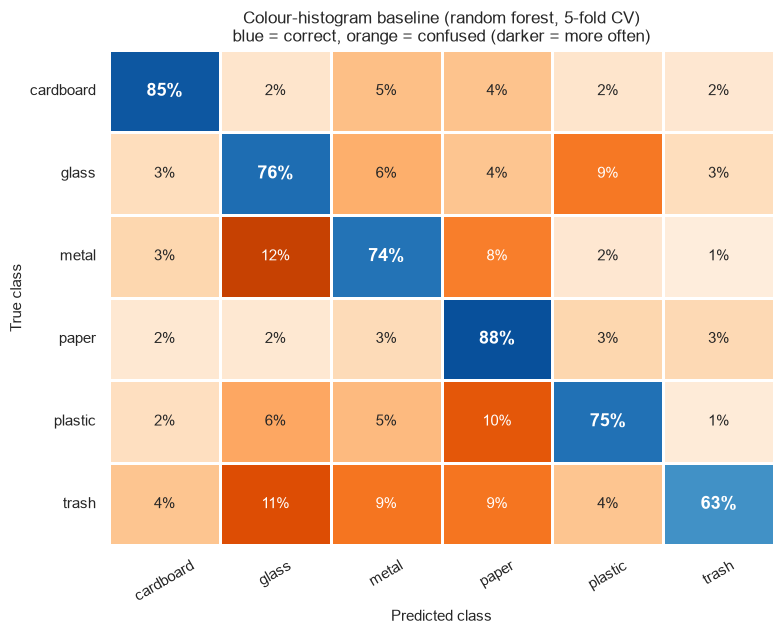

In [20]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
models = {
    "Dummy (most frequent)": DummyClassifier(strategy="most_frequent"),
    "LogReg": make_pipeline(StandardScaler(),
                            LogisticRegression(max_iter=2000, class_weight="balanced")),
    "RandomForest": RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                           random_state=SEED, n_jobs=-1),
}
res = {}
for name, m in models.items():
    pred = cross_val_predict(m, X_hist, y, cv=cv)
    res[name] = {"accuracy": accuracy_score(y, pred),
                 "macro_F1": f1_score(y, pred, average="macro")}
    if name == "RandomForest":
        rf_pred = pred
display(pd.DataFrame(res).T.round(3))
print(classification_report(y, rf_pred, labels=CLASSES))

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y, rf_pred, labels=CLASSES, normalize="true")
cm_df = pd.DataFrame(cm, index=CLASSES, columns=CLASSES)
is_diag = np.eye(len(CLASSES), dtype=bool)

fig, ax = plt.subplots(figsize=(8, 6.5))
# Correct predictions (diagonal) in blue
sns.heatmap(cm_df, mask=~is_diag, cmap="Blues", vmin=0, vmax=1, cbar=False,
            annot=True, fmt=".0%", annot_kws={"fontsize": 13, "fontweight": "bold"},
            linewidths=2, linecolor="white", ax=ax)
# Mistakes (off-diagonal) in orange: the stronger the orange, the bigger the confusion
sns.heatmap(cm_df, mask=is_diag, cmap="Oranges", vmin=0, vmax=0.15, cbar=False,
            annot=True, fmt=".0%", annot_kws={"fontsize": 11},
            linewidths=2, linecolor="white", ax=ax)
ax.grid(False)
ax.set_xlabel("Predicted class", fontsize=11)
ax.set_ylabel("True class", fontsize=11)
ax.tick_params(axis="x", rotation=30)
ax.tick_params(axis="y", rotation=0)
ax.set_title("Colour-histogram baseline (random forest, 5-fold CV)\n"
             "blue = correct, orange = confused (darker = more often)", fontsize=12)
plt.tight_layout()
plt.savefig(FIG_DIR / "09_cm_color_hist.png", dpi=150)
plt.show()

#### Result: colour alone recognises 4 out of 5 images

> **Macro-F1 = 0.77 · Accuracy = 0.79** (random forest), compared with macro-F1 0.06 / accuracy 0.24 for the dummy classifier.

**Findings**
- Colour carries a lot of information. The non-linear random forest clearly beats the linear logistic regression (macro-F1 0.64), so colour bins must be *combined* to be useful.
- **Cardboard** (F1 0.86) and **paper** (0.83) are recognised best; **trash** (0.63) is the hardest class (mixed objects, fewest images).
- The largest confusions are **metal → glass (12 %)**, **trash → glass (11 %)**, **plastic → paper (10 %)** and **glass → plastic (9 %)**. The glass/metal/plastic confusions confirm the shared bluish-grey bin and the low Bhattacharyya distances; plastic → paper was not predicted by the distances and shows that pale plastic and paper can look alike.
- Part of the score may come from shortcuts (background tint, cardboard close-ups), so it may overestimate performance on real photos.

#### Which colour histogram works better? HSV (128) vs RGB (768)
A common alternative is one 256-bin histogram per R, G and B channel, concatenated into **1 × 768**. We compare both with the same model and the same cross-validation.

In [21]:
def rgb_histogram(img_rgb, bins=256):
    """256 bins per R, G, B channel, concatenated -> 768 numbers that sum to 1."""
    hists = [cv2.calcHist([img_rgb], [c], None, [bins], [0, 256]).flatten() for c in range(3)]
    vec = np.concatenate(hists)
    return vec / vec.sum()

X_rgb = extract_features(df["path"], fn=rgb_histogram)
print("RGB feature matrix:", X_rgb.shape)

rf = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=SEED, n_jobs=-1)
comparison = {}
for name, X in [("HSV 8×4×4 (128)", X_hist), ("RGB 3×256 (768)", X_rgb)]:
    pred = cross_val_predict(rf, X, y, cv=cv)
    comparison[name] = {"features": X.shape[1],
                        "accuracy": accuracy_score(y, pred),
                        "macro_F1": f1_score(y, pred, average="macro")}
pd.DataFrame(comparison).T.astype({"features": int}).round(3)

RGB feature matrix: (2527, 768)


,features,accuracy,macro_F1
HSV 8×4×4 (128),128,0.789,0.77
RGB 3×256 (768),768,0.709,0.69


#### Result: HSV beats RGB with 6× fewer numbers

> **HSV (128 features): macro-F1 = 0.77** vs **RGB (768 features): macro-F1 = 0.69**

**Findings**
- HSV scores **8 percentage points higher** on both accuracy and macro-F1, while using only 128 instead of 768 numbers per image.
- Each HSV bin describes a **whole colour** (e.g. "muted bright orange"), while the RGB histograms count each channel separately and lose how the channels combine. Hue is also separated from brightness, which makes HSV more robust to lighting.
- **Decision:** we use the **HSV colour histogram (1 × 128)** as our colour feature.

**Conclusion of the colour analysis:** colour is informative but not enough on its own, because shape and texture are missing. This motivates the CNN and transfer-learning models, which must beat the benchmark **macro-F1 = 0.77**.

## 5. Preparing for modelling
### Train/validation/test split
One fixed split for the whole team, made by `split_dataset()` in `src/data_utils.py`: stratified 70/15/15 per class, exact duplicates removed, same seed = same split.

In [22]:
train, val, test = split_dataset(seed=SEED)
splits = pd.DataFrame(
    [(p, l, "train") for p, l in train] +
    [(p, l, "val") for p, l in val] +
    [(p, l, "test") for p, l in test],
    columns=["path", "label", "split"])
display(pd.crosstab(splits["label"], splits["split"], margins=True))

# Check 1: no identical file in two splits (must be 0)
splits["md5"] = [hashlib.md5(Path(p).read_bytes()).hexdigest() for p in splits["path"]]
assert splits["md5"].duplicated().sum() == 0

# Check 2: near-identical photos that ended up in different splits (report it)
splits["ahash"] = [average_hash(p) for p in splits["path"]]
leaks = (splits.groupby("ahash")["split"].nunique() > 1).sum()
print("Near-duplicate groups spread over several splits:", leaks)

# Save with paths relative to the project, so the CSV works on every computer
splits["path"] = [Path(p).resolve().relative_to(ROOT).as_posix() for p in splits["path"]]
splits[["path", "label", "split"]].to_csv(PROC_DIR / "splits.csv", index=False)
print("Saved:", PROC_DIR / "splits.csv")

split,test,train,val,All
label,,,,
cardboard,61,282,60,403
glass,76,350,75,501
metal,62,286,61,409
paper,90,415,89,594
plastic,72,336,72,480
trash,21,95,21,137
All,382,1764,378,2524


Near-duplicate groups spread over several splits: 0
Saved: c:\_study\Trash\trashnet-ml-project\data\processed\splits.csv


**Findings**
- **2,524 images** after removing the 3 duplicates: **1,764 train / 378 validation / 382 test**, with every class at about 70/15/15.
- Metal (409) and plastic (480) each lost the duplicate copies that were also labelled glass.
- No identical file and no near-duplicate group appears in more than one split.

## Summary and recommendations

**The data.** 2,527 clean, uniform images (512 × 384 RGB, none corrupt), but **imbalanced**: paper 594 vs trash 137 (ratio 4.34). Three photos appear twice under different labels; only one copy is kept in the split.

**The images.** Mostly single objects on plain grey/beige backgrounds, cleaner than real app photos. Possible **shortcut**: 37 % of cardboard images are close-ups without background (vs 0.2 % of the other classes). TrashNet is much brighter than ImageNet.

**Colour alone.** HSV histograms (1 × 128) beat RGB (1 × 768): **macro-F1 0.77 vs 0.69**. Cardboard and paper are recognised best; glass, metal and plastic are confused most, as the heatmap, distance matrix and t-SNE predicted; trash is hardest (F1 0.63). Colour is strong but cannot see shape or texture.

| Finding | Consequence |
|---|---|
| Imbalanced classes | Stratified split, macro-F1, class weights |
| Mislabelled duplicates | One copy kept, errors documented |
| Plain backgrounds, cardboard close-ups | Crop/zoom/colour augmentation |
| Glass/metal/plastic confused by colour | CNN needed for shape and texture |
| Brighter than ImageNet | TrashNet normalisation for our CNN, ImageNet for pretrained models |

**Next steps**
1. All models use the shared split from `split_dataset()` (or `data/processed/splits.csv`).
2. CNN and transfer learning must beat **macro-F1 = 0.77**.
3. Resize to 224 × 224, normalise, and augment (rotation, flips, colour jitter, crop/zoom).
4. Report per-class recall and confusion matrices, focusing on trash and glass/metal/plastic.